# Plotting point locations on histology slices

This example walks through various ways to display the 3D location of points, such as clusters or cells, on histology slices

## Data Preparation

For all examples below the xyz coordinates of each point and an array of values must be provided. The cell below makes stand-in points along a probe-like line, with a stand-in firing rate and amplitude for each; replace them with your own coordinates (in metres relative to bregma) and values.

In [1]:
from iblatlas.atlas import AllenAtlas
import numpy as np

ba = AllenAtlas()

# Stand-in for your own data: 300 points along a straight line from secondary motor cortex down to
# the bed nuclei of the stria terminalis, jittered by about 30 µm. Columns are ML, AP, DV in metres.
rng = np.random.default_rng(42)
depth = np.sort(rng.uniform(0, 1, 300))
start, end = np.array([-0.0008, 0.0004, -0.0006]), np.array([-0.0011, 0.0004, -0.0055])
xyz_full = start + depth[:, np.newaxis] * (end - start) + rng.normal(0, 30e-6, (300, 3))
firing_rate = rng.gamma(2, 5, 300)  # Hz
amplitude = rng.uniform(50e-6, 300e-6, 300)  # V

# Here we will set all ap values to a chosen value for visualisation purposes
xyz = np.c_[xyz_full[:, 0], np.ones(len(xyz_full)) * 400 / 1e6, xyz_full[:, 2]]
values = firing_rate

## Example 1: Aggregation methods

The values of points that lie within the same voxel within the volume can be aggregated together in different ways by changing the `aggr` argument. Below shows an example where values in each voxel have been aggregated according to the average firing rate of the points (left) and according to the count of points in each voxel (right)

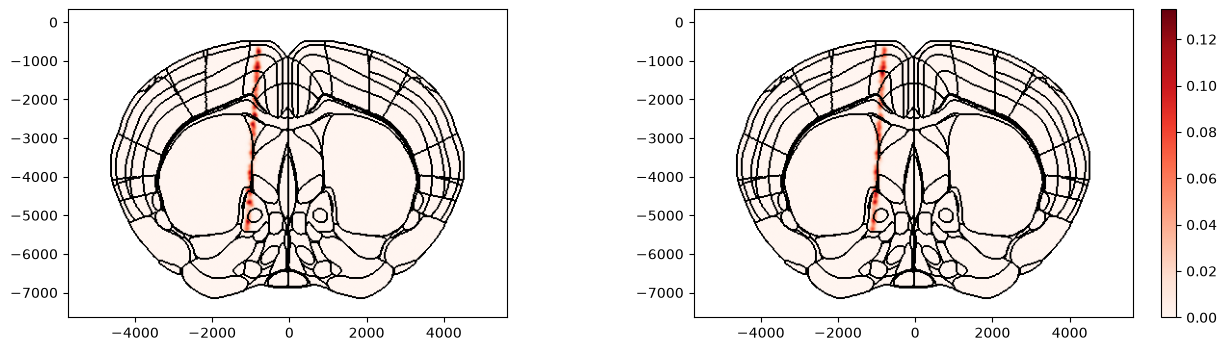

In [2]:
from iblatlas.plots import plot_points_on_slice
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(16,4))

# Plot points on the coronal slice at ap=400um overlaid overlaid on brain region boundaries using Allen mapping 
# and a 3D gaussian kernel with fwhm=100um is applied

# Values in the same voxel are aggregated by the mean
fig, ax = plot_points_on_slice(xyz, values=values, coord=400, slice='coronal', mapping='Allen', background='boundary', 
                               cmap='Reds', aggr='mean', fwhm=100, brain_atlas=ba, ax=axs[0])

# Values in the same voxel are aggregated by the count
# N.B. can also pass values=None in this case as they are not used in the computation
fig, ax, cbar = plot_points_on_slice(xyz, values=values, coord=400, slice='coronal', mapping='Allen', background='boundary', 
                               cmap='Reds', aggr='count', fwhm=100, brain_atlas=ba, ax=axs[1], show_cbar=True)

The different options for aggregation are listed in the docstring of the function

In [3]:
help(plot_points_on_slice)

Help on function plot_points_on_slice in module iblatlas.plots:

plot_points_on_slice(xyz, values=None, coord=-1000, slice='coronal', mapping='Allen', background='boundary', cmap='Reds', clevels=None, show_cbar=False, aggr='mean', fwhm=100, brain_atlas=None, ax=None)
    Plot xyz points on slice. Points that lie in the same voxel within slice are aggregated according to method specified.
    A 3D Gaussian smoothing kernel with distance specified by fwhm is applied to images.

    :param xyz: 3 column array of xyz coordinates of points in metres
    :param values: array of values per xyz coordinates, if no values are given the sum of xyz points in each voxel is
    returned
    :param coord: coordinate of slice in um (not needed when slice='top')
    :param slice: orientation of slice, options are 'coronal', 'sagittal', 'horizontal', 'top' (top view of brain)
    :param mapping: atlas mapping to use, options are 'Allen', 'Beryl' or 'Cosmos'
    :param background: background slice to ove

## Example 2: Applying gaussian kernels with varying FWHM

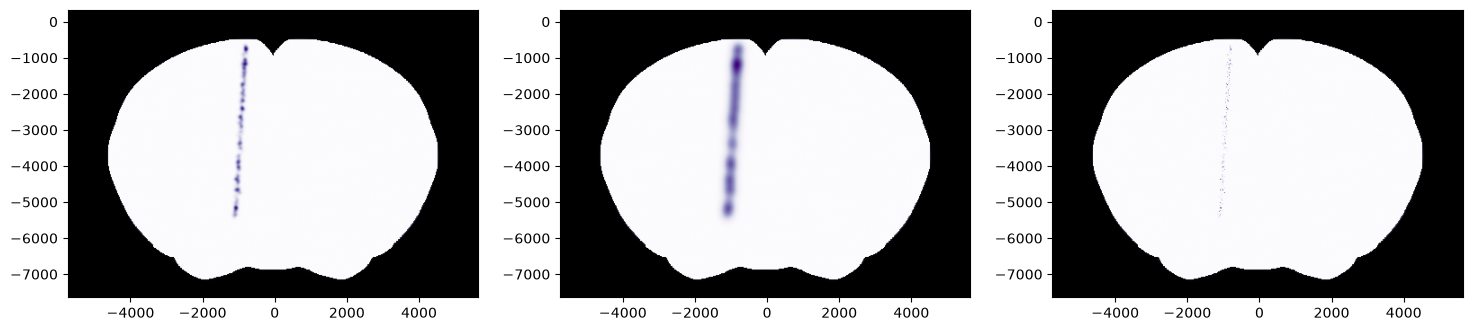

In [4]:
# Plot points on the coronal slice at ap=400um overlaid overlaid on Allen dwi image using Cosmos mapping with
# values aggregated by max

figs, axs = plt.subplots(1, 3, figsize=(18,4))

# FWHM of 100 um
fig, ax = plot_points_on_slice(xyz, values=values, coord=400, slice='coronal', background='image', 
                               cmap='Purples', aggr='max', fwhm=100, brain_atlas=ba, ax=axs[0])

# FWHM of 300 um
fig, ax = plot_points_on_slice(xyz, values=values, coord=400, slice='coronal', background='image', 
                               cmap='Purples', aggr='max', fwhm=300, brain_atlas=ba, ax=axs[1])

# FWHM of 0 um
# if fwhm=0 no gaussian kernal applied
fig, ax = plot_points_on_slice(xyz, values=values, coord=400, slice='coronal', background='image', 
                               cmap='Purples', aggr='max', fwhm=0, brain_atlas=ba, ax=axs[2])

## Example 3: Precomputing Volume

Convolving the 3D volume with the gaussian kernal can take some time to compute, particularly when using a large fwhm value. When exploring the same volume at different coordinates and using different slices it is recommended to precompute the volume and then plot the slices. Below shows an example of how to do this.

In [5]:
from iblatlas.plots import compute_volume_from_points, plot_volume_on_slice

# Use the full coordinates and the stand-in amplitude
xyz = xyz_full
values = amplitude

# Compute volume
volume = compute_volume_from_points(xyz, values=values, aggr='mean', fwhm=250, ba=ba)

Text(0.5, 1.0, 'ap = 500um')

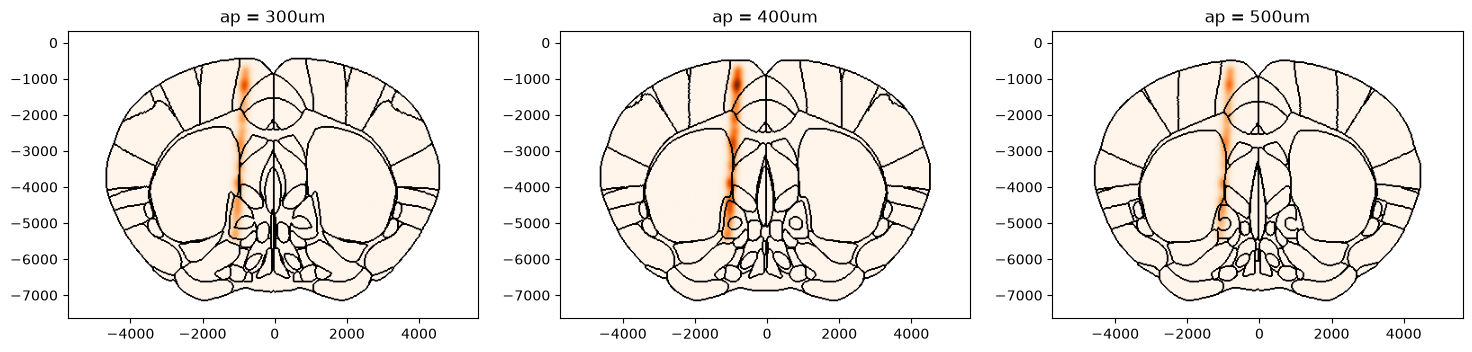

In [6]:
# Plot points on the coronal slices on brain region boundaries using Beryl maping
figs, axs = plt.subplots(1, 3, figsize=(18,4))
fig, ax = plot_volume_on_slice(volume, coord=300, slice='coronal', mapping='Beryl', background='boundary', 
                               cmap='Oranges', brain_atlas=ba, ax=axs[0])
ax.set_title('ap = 300um')
fig, ax = plot_volume_on_slice(volume, coord=400, slice='coronal', mapping='Beryl', background='boundary', 
                               cmap='Oranges', brain_atlas=ba, ax=axs[1])
ax.set_title('ap = 400um')
fig, ax = plot_volume_on_slice(volume, coord=500, slice='coronal', mapping='Beryl', background='boundary', 
                               cmap='Oranges', brain_atlas=ba,ax=axs[2])
ax.set_title('ap = 500um')

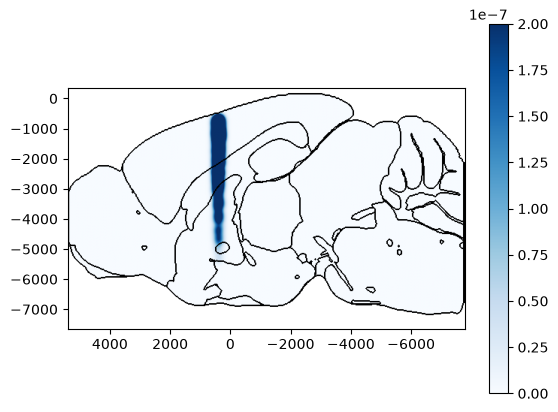

In [7]:
# Plot points on the saggital slice at ap=-800um overlaid on brain region boundaries using Cosmos mapping
fig, ax, cbar = plot_volume_on_slice(volume, coord=-800, slice='sagittal', mapping='Cosmos', background='boundary', 
                               cmap='Blues', brain_atlas=ba, clevels=[0, 2e-7], show_cbar=True)

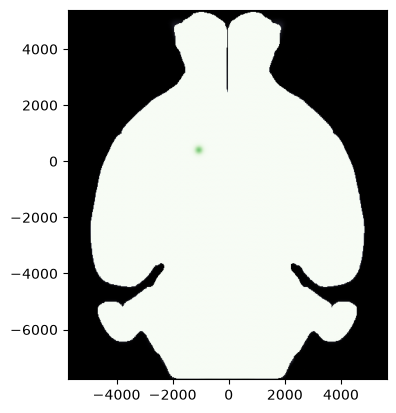

In [8]:
# Plot points on the horizontal slice at dv=-5000um overlaid on allen dwi image
fig, ax = plot_volume_on_slice(volume, coord=-5000, slice='horizontal', background='image', cmap='Greens', brain_atlas=ba)